## Decision Tree Definition

A Decision Tree is a supervised machine learning algorithm used for
classification and regression problems.

It makes predictions by repeatedly splitting the dataset based on feature
conditions. The structure of a Decision Tree contains:

- Root Node: The starting point of the tree.
- Decision Node: A node where the data is split based on a condition.
- Branch: Represents the result of a decision.
- Leaf Node: Represents the final prediction.

### Basic Working Steps

1. Select the best feature for splitting the dataset.
2. Split the dataset into subsets based on the selected feature.
3. Repeat the splitting process for each child node.
4. Stop when a stopping condition is reached and create leaf nodes.
5. Use the leaf node to make the final prediction.

                   Petal Length?
                  /             \
              Small              Large
                |                  |
             Setosa          Petal Width?
                            /            \
                        Small             Large
                          |                 |
                     Versicolor         Virginica

### Data Loading and Basic EDA

In [5]:
import pandas as pd

# Load the CSV dataset
df = pd.read_csv("house_prices_dataset.csv")

# Display first 5 rows
display(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate values
print("\nDuplicate Values:", df.duplicated().sum())

,square_feet,num_rooms,age,distance_to_city(km),price
0,2248.357077,3,92,22.997972,200374.0904
1,1930.867849,2,22,13.984254,268784.8473
2,2323.844269,6,33,21.500945,315020.8577
3,2761.514928,3,63,10.343638,355111.4685
4,1882.923313,7,54,25.485200,234197.1239


Dataset Shape: (10000, 5)

Missing Values:
square_feet             0
num_rooms               0
age                     0
distance_to_city(km)    0
price                   0
dtype: int64

Duplicate Values: 0


### EDA

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   square_feet           10000 non-null  float64
 1   num_rooms             10000 non-null  int64  
 2   age                   10000 non-null  int64  
 3   distance_to_city(km)  10000 non-null  float64
 4   price                 10000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 390.8 KB

Statistical Summary:


,square_feet,num_rooms,age,distance_to_city(km),price
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1999.147496,4.49510,49.516900,15.362148,263011.571609
std,501.021194,1.71116,28.992336,8.325101,98336.945117
min,500.000000,2.00000,0.000000,1.000161,-95613.138250
25%,1663.704735,3.00000,24.000000,8.121636,196791.510700
50%,1998.702513,4.00000,49.000000,15.403146,262497.361250
75%,2335.540444,6.00000,75.000000,22.447530,330445.581875
max,3963.118853,7.00000,99.000000,29.993892,660168.255600


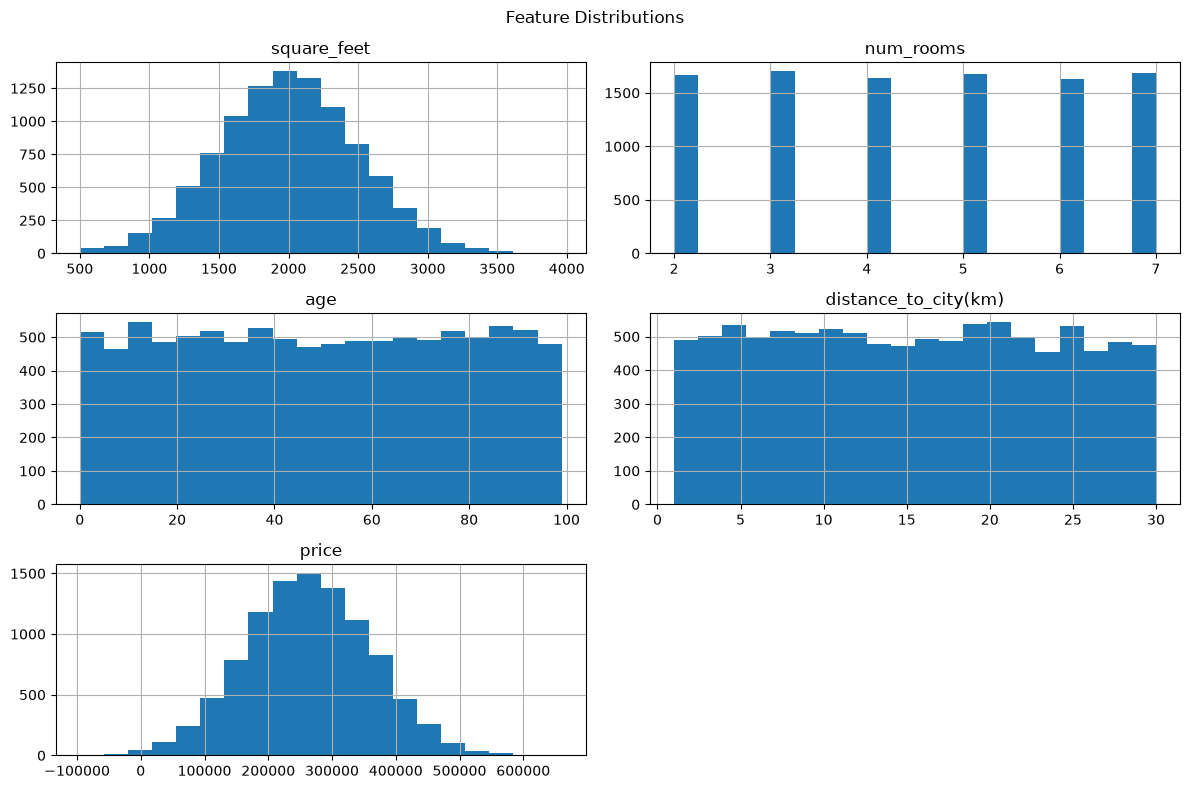


Correlation Matrix:


,square_feet,num_rooms,age,distance_to_city(km),price
square_feet,1.000000,-0.006982,0.009760,0.004638,0.756545
num_rooms,-0.006982,1.000000,0.005636,0.016747,0.335230
age,0.009760,0.005636,1.000000,0.011175,-0.290799
distance_to_city(km),0.004638,0.016747,0.011175,1.000000,-0.418217
price,0.756545,0.335230,-0.290799,-0.418217,1.000000


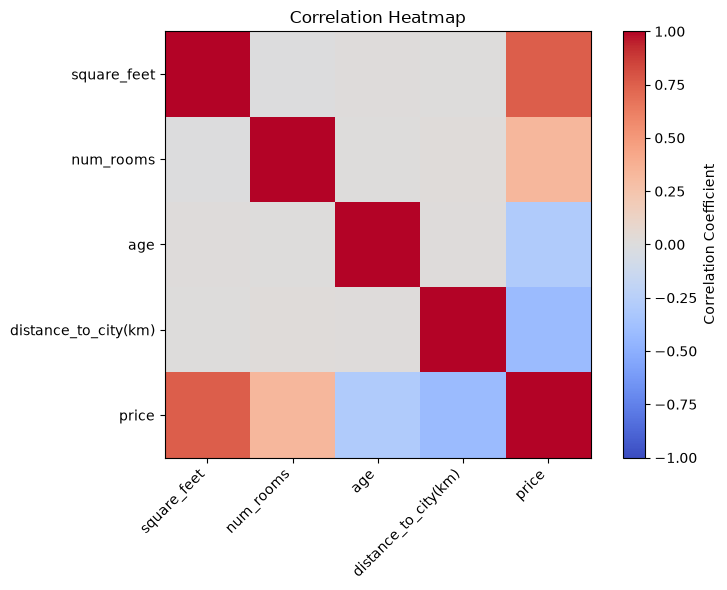

In [6]:
# Step 1: Check data types and dataset information
print("Dataset Information:")
df.info()

# Step 2: Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Step 3: Visualize feature distributions
df.hist(figsize=(12, 8), bins=20)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

# Step 4: Correlation analysis
correlation = df.corr(numeric_only=True)

print("\nCorrelation Matrix:")
display(correlation)

# Step 5: Visualize correlations
plt.figure(figsize=(8, 6))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation Coefficient")
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [7]:
negative_prices = df[df["price"] < 0]

print("Negative price records:", len(negative_prices))
print("Percentage:", round(len(negative_prices) / len(df) * 100, 2))

display(negative_prices.head())

Negative price records: 38
Percentage: 0.38


,square_feet,num_rooms,age,distance_to_city(km),price
262,500.000000,3,76,12.561114,-14286.956410
471,849.039418,2,23,29.665812,-33373.818650
568,1064.604039,2,95,16.698572,-174.815934
740,1079.562884,3,93,27.508514,-23998.186170
978,1208.048588,2,78,24.380592,-11237.108060


### Split the dataset

**# Separate independent and dependent variables**

In [8]:
X = df.drop(columns=["price"])
y = df["price"]

# Split into training and testing datasets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 4)
Testing Data: (2000, 4)


**Build and train the Decision Tree**

In [9]:
from sklearn.tree import DecisionTreeRegressor

# Create Decision Tree model
dt_model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=3,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


**Visualize the Decision Tree**

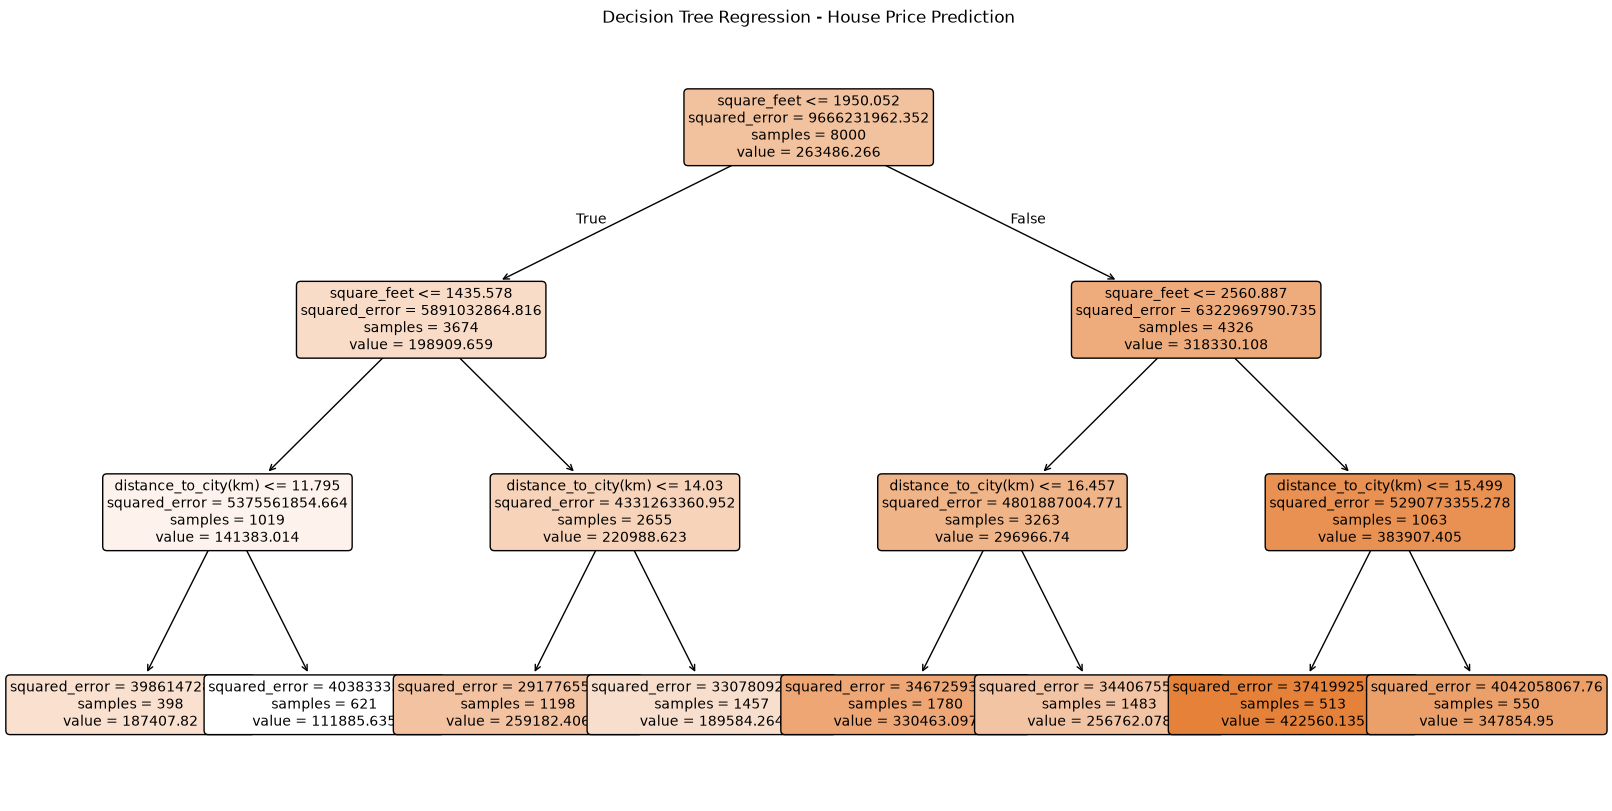

In [10]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Regression - House Price Prediction")
plt.show()

### Decision Tree Model Interpretation

The Decision Tree Regressor was trained using 8,000 samples
and tested using 2,000 samples.

The root node selected square_feet as the first splitting
feature, with a threshold of approximately 1950.052.

The model recursively split the dataset using square_feet
and distance_to_city(km).

The model achieved:
- MAE: 47259.68
- MSE: 3423325294.20
- RMSE: 58509.19
- R² Score: 0.6462

The R² score indicates that the model explains approximately
64.62% of the variation in house prices in the test dataset.

Further improvements will be explored through pruning
and hyperparameter tuning.

**Make predictions and evaluate**

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict house prices
y_pred = dt_model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 47259.68264770147
Mean Squared Error: 3423325294.204706
Root Mean Squared Error: 58509.18982693835
R2 Score: 0.6462229326041622


# Topic 2: Information Gain in Decision Trees

### Information Gain - Manual Calculation Using Python

In [12]:
import numpy as np

# Function to calculate entropy
def calculate_entropy(labels):
    values, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()

    return -np.sum(probabilities * np.log2(probabilities))


# Example dataset: 0 = Low Price, 1 = High Price
parent = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]

left_child = [1, 1, 1, 1, 0]
right_child = [1, 0, 0, 0, 0]

# Calculate entropy
parent_entropy = calculate_entropy(parent)
left_entropy = calculate_entropy(left_child)
right_entropy = calculate_entropy(right_child)

# Calculate weighted entropy
weighted_entropy = (
    len(left_child) / len(parent) * left_entropy
    + len(right_child) / len(parent) * right_entropy
)

# Calculate information gain
information_gain = parent_entropy - weighted_entropy

print("Parent Entropy:", round(parent_entropy, 4))
print("Left Child Entropy:", round(left_entropy, 4))
print("Right Child Entropy:", round(right_entropy, 4))
print("Information Gain:", round(information_gain, 4))

Parent Entropy: 1.0
Left Child Entropy: 0.7219
Right Child Entropy: 0.7219
Information Gain: 0.2781


### Information Gain using your actual House Prices dataset

In [13]:
# Access the trained Decision Tree
tree = dt_model.tree_

# Root node and its children
root = 0
left = tree.children_left[root]
right = tree.children_right[root]

# Number of training samples
n_parent = tree.weighted_n_node_samples[root]
n_left = tree.weighted_n_node_samples[left]
n_right = tree.weighted_n_node_samples[right]

# Squared error impurity
parent_error = tree.impurity[root]
left_error = tree.impurity[left]
right_error = tree.impurity[right]

# Weighted child impurity
weighted_child_error = (
    (n_left / n_parent) * left_error
    + (n_right / n_parent) * right_error
)

# Impurity reduction
error_reduction = parent_error - weighted_child_error

print("Parent Squared Error:", round(parent_error, 2))
print("Weighted Child Squared Error:", round(weighted_child_error, 2))
print("Squared Error Reduction:", round(error_reduction, 2))

print("\nRoot Splitting Feature:",
      X.columns[tree.feature[root]])

print("Root Split Threshold:",
      round(tree.threshold[root], 3))

Parent Squared Error: 9666231962.35
Weighted Child Squared Error: 6124602757.51
Squared Error Reduction: 3541629204.85

Root Splitting Feature: square_feet
Root Split Threshold: 1950.052


# Topic 3: Entropy

### Calculate entropy for different class distributions

In [14]:
import numpy as np

def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()

    return -np.sum(probabilities * np.log2(probabilities))

# Example 1: Pure node
pure_node = [1, 1, 1, 1, 1]

# Example 2: Mixed node
mixed_node = [1, 1, 1, 0, 0]

# Example 3: Equally distributed classes
equal_node = [1, 1, 1, 0, 0, 0]

print("Pure Node Entropy:", round(entropy(pure_node), 4))
print("Mixed Node Entropy:", round(entropy(mixed_node), 4))
print("Equal Node Entropy:", round(entropy(equal_node), 4))

Pure Node Entropy: -0.0
Mixed Node Entropy: 0.971
Equal Node Entropy: 1.0


### Visualize how entropy changes

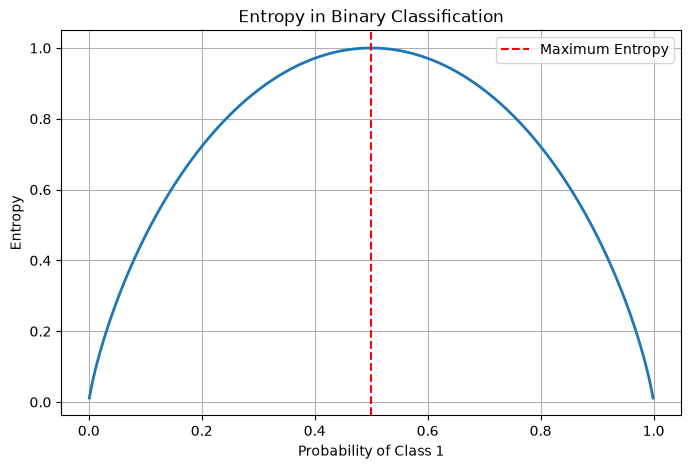

In [15]:
import matplotlib.pyplot as plt

p = np.linspace(0.001, 0.999, 500)

entropy_values = (
    -p * np.log2(p)
    -(1-p) * np.log2(1-p)
)

plt.figure(figsize=(8, 5))

plt.plot(p, entropy_values, linewidth=2)
plt.axvline(0.5, linestyle="--", color="red",
            label="Maximum Entropy")

plt.xlabel("Probability of Class 1")
plt.ylabel("Entropy")
plt.title("Entropy in Binary Classification")
plt.legend()
plt.grid(True)
plt.show()

# topic4: Pre-Pruning and Post-Pruning

### Pre-Pruning

## Pre-Pruning

Pre-Pruning is a technique that prevents a Decision Tree from
growing too complex by setting restrictions before training.

Common hyperparameters:
- max_depth
- min_samples_split
- min_samples_leaf
- max_leaf_nodes

In [16]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

pre_pruned_tree = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

pre_pruned_tree.fit(X_train, y_train)

pre_pred = pre_pruned_tree.predict(X_test)

print("Pre-Pruning Results")
print("Tree Depth:", pre_pruned_tree.get_depth())
print("Leaf Nodes:", pre_pruned_tree.get_n_leaves())
print("MSE:", mean_squared_error(y_test, pre_pred))
print("R2 Score:", r2_score(y_test, pre_pred))

Pre-Pruning Results
Tree Depth: 5
Leaf Nodes: 32
MSE: 2033560100.7978022
R2 Score: 0.789845583751174


### Post-Pruning

In [17]:
# Grow a tree without pre-pruning restrictions
full_tree = DecisionTreeRegressor(random_state=42)
full_tree.fit(X_train, y_train)

# Obtain candidate pruning strengths
path = full_tree.cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

# Choose an illustrative pruning strength
post_pruned_tree = DecisionTreeRegressor(
    ccp_alpha=1000000,
    random_state=42
)

post_pruned_tree.fit(X_train, y_train)

post_pred = post_pruned_tree.predict(X_test)

print("Post-Pruning Results")
print("Tree Depth:", post_pruned_tree.get_depth())
print("Leaf Nodes:", post_pruned_tree.get_n_leaves())
print("MSE:", mean_squared_error(y_test, post_pred))
print("R2 Score:", r2_score(y_test, post_pred))

Post-Pruning Results
Tree Depth: 11
Leaf Nodes: 342
MSE: 977693457.9794967
R2 Score: 0.898962121723686


### Compare the models

In [18]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Original (Depth 3)", "Pre-Pruning", "Post-Pruning"],
    "Depth": [
        dt_model.get_depth(),
        pre_pruned_tree.get_depth(),
        post_pruned_tree.get_depth()
    ],
    "Leaf Nodes": [
        dt_model.get_n_leaves(),
        pre_pruned_tree.get_n_leaves(),
        post_pruned_tree.get_n_leaves()
    ],
    "R2 Score": [
        r2_score(y_test, dt_model.predict(X_test)),
        r2_score(y_test, pre_pred),
        r2_score(y_test, post_pred)
    ]
})

display(comparison)

,Model,Depth,Leaf Nodes,R2 Score
0,Original (Depth 3),3,8,0.646223
1,Pre-Pruning,5,32,0.789846
2,Post-Pruning,11,342,0.898962


### Pre-Pruning vs Post-Pruning Results

The original Decision Tree achieved an R² score of 0.6462
with a maximum depth of 3.

The pre-pruned Decision Tree achieved an R² score of 0.7898
with a depth of 5 and 32 leaf nodes.

The post-pruned Decision Tree achieved the highest test R²
score of 0.8990 with a depth of 11 and 342 leaf nodes.

The results show that increasing model complexity improved
performance for these tested configurations.

However, a more complex tree can also overfit the training
data. Cross-validation will be used to select appropriate
hyperparameters.

# Topic 5: Gini Impurity and Gini Index

### Calculate Gini Impurity using Python

In [19]:
import numpy as np

def calculate_gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()

    return 1 - np.sum(probabilities ** 2)

# Example datasets
pure_node = [1, 1, 1, 1, 1]
mixed_node = [1, 1, 1, 0, 0]
equal_node = [1, 1, 1, 0, 0, 0]

print("Pure Node Gini:", round(calculate_gini(pure_node), 4))
print("Mixed Node Gini:", round(calculate_gini(mixed_node), 4))
print("Equal Node Gini:", round(calculate_gini(equal_node), 4))

Pure Node Gini: 0.0
Mixed Node Gini: 0.48
Equal Node Gini: 0.5


### Calculate Gini Index for a split

In [20]:
parent = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]

left_child = [1, 1, 1, 1, 0]
right_child = [1, 0, 0, 0, 0]

parent_gini = calculate_gini(parent)

weighted_gini = (
    len(left_child) / len(parent) * calculate_gini(left_child)
    + len(right_child) / len(parent) * calculate_gini(right_child)
)

gini_reduction = parent_gini - weighted_gini

print("Parent Gini:", round(parent_gini, 4))
print("Weighted Gini Index:", round(weighted_gini, 4))
print("Gini Reduction:", round(gini_reduction, 4))

Parent Gini: 0.5
Weighted Gini Index: 0.32
Gini Reduction: 0.18


### Visualize Gini Impurity

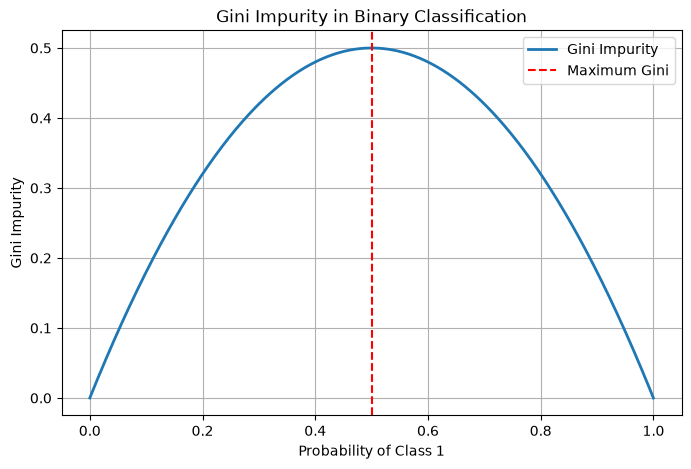

In [22]:
import matplotlib.pyplot as plt

p = np.linspace(0, 1, 500)

gini_values = 1 - (p**2 + (1-p)**2)

plt.figure(figsize=(8, 5))
plt.plot(p, gini_values, label="Gini Impurity", linewidth=2)
plt.axvline(0.5, color="red", linestyle="--",
            label="Maximum Gini")

plt.xlabel("Probability of Class 1")
plt.ylabel("Gini Impurity")
plt.title("Gini Impurity in Binary Classification")
plt.legend()
plt.grid(True)
plt.show()

# Topic 6: Hyperparameter Tuning in Decision Trees

### Define the parameter grid

In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "ccp_alpha": [0.0, 10000, 100000]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation R2:", grid_search.best_score_)

Best Parameters: {'ccp_alpha': 0.0, 'max_depth': 15, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best Cross-Validation R2: 0.9062264698567789


### Evaluate the tuned model

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_test)

print("Tuned Decision Tree Results")
print("MAE:", mean_absolute_error(y_test, tuned_predictions))
print("MSE:", mean_squared_error(y_test, tuned_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, tuned_predictions)))
print("R2 Score:", r2_score(y_test, tuned_predictions))

print("\nTree Depth:", best_model.get_depth())
print("Leaf Nodes:", best_model.get_n_leaves())

Tuned Decision Tree Results
MAE: 22699.210805871753
MSE: 821685106.3796592
RMSE: 28665.050259499967
R2 Score: 0.9150845092781738

Tree Depth: 15
Leaf Nodes: 1265


### Compare the original and tuned models

In [25]:
comparison = pd.DataFrame({
    "Model": ["Original Decision Tree", "Tuned Decision Tree"],
    "R2 Score": [
        r2_score(y_test, dt_model.predict(X_test)),
        r2_score(y_test, tuned_predictions)
    ],
    "MAE": [
        mean_absolute_error(y_test, dt_model.predict(X_test)),
        mean_absolute_error(y_test, tuned_predictions)
    ],
    "Depth": [
        dt_model.get_depth(),
        best_model.get_depth()
    ],
    "Leaf Nodes": [
        dt_model.get_n_leaves(),
        best_model.get_n_leaves()
    ]
})

display(comparison)

,Model,R2 Score,MAE,Depth,Leaf Nodes
0,Original Decision Tree,0.646223,47259.682648,3,8
1,Tuned Decision Tree,0.915085,22699.210806,15,1265


## Final Conclusion

In this project, I implemented Decision Tree Regression
using the House Prices dataset.

I explored the concepts of Entropy, Information Gain,
Gini Impurity, Pre-Pruning, Post-Pruning, and
Hyperparameter Tuning.

I trained an initial Decision Tree model and achieved
an R² score of 0.6462.

After applying GridSearchCV with 5-fold cross-validation,
I obtained a tuned model with an R² score of 0.9151.

The Mean Absolute Error decreased from 47259.68
to 22699.21, representing an improvement of approximately 52%.

The results demonstrate how hyperparameter tuning can
improve prediction performance while controlling model
complexity.

Entropy and Gini Impurity were demonstrated separately
using classification examples, while squared error was
used for the regression task.